# Análisis de precios de perfumes en Falabella con web scraping

**Equipo:** Santiago Sanchez Salazar y Anderson Gaviria Bedoya · Programación para análisis de datos · Evidencia 1

> **Nota de entorno:** este notebook se probó en Jupyter local (Windows 11) con
> Python 3.13.14, Selenium 4.51.0, pandas 3.1.0 y matplotlib 3.11.2.

Este notebook usa **Selenium** para extraer información de productos de la tienda
Falabella (falabella.com.co), y **requests + BeautifulSoup** para verificarla. El
objetivo es determinar qué tan buena compra es el perfume **Khamrah de Lattafa
100 ml** frente a otros cuatro perfumes de la misma marca, a partir de su precio,
su descuento y la calificación de los compradores.

El informe que acompaña a este notebook explica el problema, los objetivos, la
metodología y las conclusiones.

## Descripción de la página y del artículo

**La página:** Falabella (falabella.com.co) es una de las tiendas por internet más
grandes de Colombia y Latinoamérica. Funciona como un "marketplace": vende productos
propios y también deja que vendedores externos publiquen sus productos en la misma
plataforma. En este caso, los perfumes los vende un vendedor externo llamado
"Amber Oud".

**El artículo:** Perfume Khamrah de la marca Lattafa, presentación de 100 ml. Es una
fragancia de inspiración árabe (especiada, con notas de canela, dátiles y vainilla)
de la línea de perfumes económicos que se ha vuelto muy popular. Se eligió porque
tiene precio, descuento, calificación y reseñas: datos suficientes para analizar.


## Objetivos

**¿Por qué este artículo y esta empresa?** El Khamrah se publica con un descuento
cercano al 60% y tiene una calificación respaldada por 322 reseñas: es un buen caso
para comprobar si un descuento grande significa una buena compra. Falabella publica
en cada página de producto el precio, el precio de lista, la calificación y las
reseñas, y funciona como marketplace, así que el precio refleja la estrategia del
vendedor dentro de una de las tiendas en línea más conocidas del país.

**Objetivo general:** determinar qué tan conveniente es comprar el perfume Khamrah
de Lattafa (100 ml) en Falabella frente a otros perfumes de la misma marca, a partir
de su precio, su descuento y la calificación de los compradores, con datos
obtenidos por web scraping.

**Objetivos específicos:**

1. Extraer con web scraping el nombre, el precio final, el precio de lista, la
   calificación y el número de reseñas del Khamrah y de cuatro perfumes de la misma
   marca.
2. Calcular el porcentaje de descuento de cada perfume sobre su precio de lista.
3. Comparar el precio y la calificación del Khamrah con los de los otros perfumes.
4. Identificar qué perfume ofrece la mejor relación entre precio y calificación.

**Métricas de éxito** (cómo sabemos que la solución funcionó):

| Métrica | Cómo se mide | Meta | Resultado |
| --- | --- | --- | --- |
| Completitud | productos con los cinco campos completos / productos consultados | 100% | 5 de 5 (celda de `df.isna().sum()`) |
| Exactitud | precios iguales entre Selenium y BeautifulSoup / productos consultados | 100% | 5 de 5 (celda de comparación) |
| Respuesta a los objetivos | objetivos específicos respondidos con un dato | 4 de 4 | 4 de 4 (ver Conclusiones) |

## Metodología

Se usó **Selenium** para hacer scraping de las páginas de producto. Los pasos fueron:

1. Abrir la página del producto con un navegador Chrome controlado por Selenium
   (en modo "headless", es decir, sin abrir ventana visible).
2. Esperar a que la página termine de cargar por completo.
3. Extraer de cada producto: nombre, precio final, precio de lista (tachado),
   calificación y número de reseñas.
4. Guardar todo en una tabla (DataFrame de pandas) y calcular el % de descuento.
5. Graficar los resultados y sacar conclusiones.

Además, para verificar que los datos son correctos, el precio también se extrae con
**requests + BeautifulSoup** (leyendo el HTML directamente, sin navegador) y se
compara con el obtenido con Selenium.


## ¿Por qué usamos Selenium?

De las tres técnicas de scraping vistas (BeautifulSoup, Selenium y Scrapy) elegimos
**Selenium**. Al principio supusimos que Falabella cargaba el precio con
JavaScript; al revisar el código fuente de la página (Ctrl+U) vimos que no: el
precio ya viene en el HTML, así que BeautifulSoup también habría servido. Por eso
lo usamos para verificar los datos (más abajo).

Mantuvimos Selenium porque:

1. Abre la página igual que un navegador real: si la tienda empieza a cargar los
   precios con JavaScript o a bloquear las descargas simples, el scraper sigue
   funcionando.
2. Permite esperar de forma controlada a que los datos aparezcan antes de leerlos.
3. Permite navegar e interactuar con la página (pasar de página, hacer clic), algo
   que vamos a necesitar en las siguientes evidencias.

Scrapy no hacía falta: sirve para recorrer catálogos completos, y aquí son cinco
productos.

## Instalación (solo la primera vez)

Para correr este notebook se necesita tener instalado:

```
pip install selenium pandas matplotlib requests beautifulsoup4
```

El driver de Chrome no hay que descargarlo a mano: Selenium lo descarga solo la
primera vez que se usa (Selenium Manager).


In [1]:
# Librerías que vamos a usar
import json                                         # para leer el JSON-LD de la página
import time                                         # para dar tiempo a que cargue la página
from datetime import date                           # para la fecha de extracción

import requests                                     # para descargar el HTML (comparación)
from bs4 import BeautifulSoup                       # para leer el HTML descargado

from selenium import webdriver                      # para controlar el navegador
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By         # para buscar elementos en la página
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

import pandas as pd                                 # para armar la tabla de datos
import matplotlib.pyplot as plt                     # para hacer las gráficas

%matplotlib inline


In [2]:
# Función que crea el navegador en modo "headless" (sin abrir ventana visible)
def crear_navegador():
    opciones = Options()
    opciones.add_argument("--headless=new")            # no abre ventana
    opciones.add_argument("--window-size=1366,2000")   # tamaño de la ventana
    opciones.add_argument("--disable-gpu")
    opciones.add_argument("--no-sandbox")
    # un user-agent normal, para que la página no nos trate como bot
    opciones.add_argument(
        "--user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36"
    )
    return webdriver.Chrome(options=opciones)


In [3]:
def extraer_producto(navegador, url):
    # Abre la página de un producto y devuelve sus datos principales.
    navegador.get(url)

    # Esperamos a que aparezca el precio: así sabemos que la página ya cargó
    WebDriverWait(navegador, 25).until(
        EC.presence_of_element_located((By.CSS_SELECTOR, "[data-event-price]"))
    )
    time.sleep(2)  # margen extra para que termine de cargar todo

    # 1) Nombre del producto: está en la etiqueta <h1>
    nombre = navegador.find_element(By.TAG_NAME, "h1").text.strip()

    # 2) Precio final: la página lo guarda limpio en el atributo data-event-price
    precio = navegador.find_element(
        By.CSS_SELECTOR, "[data-event-price]"
    ).get_attribute("data-event-price")

    # 3) Precio de lista (el que aparece tachado): es un texto con clase "cros"
    pod = navegador.find_element(By.CSS_SELECTOR, "div[id^='testId-pod-prices-']")
    precio_lista = pod.find_element(By.CSS_SELECTOR, "[class*='cros']").text.strip()

    # 4) Calificación y número de reseñas: vienen en el JSON-LD de la página
    calificacion = None
    resenas = None
    sopa = BeautifulSoup(navegador.page_source, "html.parser")
    for script in sopa.find_all("script", {"type": "application/ld+json"}):
        try:
            datos = json.loads(script.string or "")
        except Exception:
            continue
        if isinstance(datos, dict) and datos.get("@type") == "Product":
            calificacion = datos.get("aggregateRating", {}).get("ratingValue")
            resenas = datos.get("aggregateRating", {}).get("reviewCount")
            break

    return {
        "nombre": nombre,
        "precio": precio,
        "precio_lista": precio_lista,
        "calificacion": calificacion,
        "resenas": resenas,
    }


In [4]:
def extraer_precio_bs4(url):
    # Extrae el precio leyendo el HTML directamente con requests + BeautifulSoup,
    # sin navegador. El precio viene dentro del JSON-LD (schema.org Product).
    headers = {
        "User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                       "AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36")
    }
    respuesta = requests.get(url, headers=headers, timeout=30)
    respuesta.raise_for_status()
    sopa = BeautifulSoup(respuesta.text, "html.parser")

    for script in sopa.find_all("script", {"type": "application/ld+json"}):
        try:
            datos = json.loads(script.string or "")
        except Exception:
            continue
        if isinstance(datos, dict) and datos.get("@type") == "Product":
            ofertas = datos.get("offers") or []
            if isinstance(ofertas, dict):
                ofertas = [ofertas]
            for oferta in ofertas:
                precio = oferta.get("price")
                if precio is not None:
                    return str(precio)
    return None


In [5]:
# Creamos el navegador una sola vez y lo reutilizamos para todos los productos
navegador = crear_navegador()

# URL del producto elegido: Perfume Khamrah Lattafa 100 ml
url_articulo = ("https://www.falabella.com.co/falabella-co/product/128762286/"
                "Perfume-Khamrah-Lattafa-100ml/128762287")

articulo = extraer_producto(navegador, url_articulo)

print("Artículo analizado:")
for campo, valor in articulo.items():
    print(f"  {campo}: {valor}")


Artículo analizado:
  nombre: Perfume Khamrah Lattafa 100ml
  precio: 119.990
  precio_lista: $ 299.000
  calificacion: 4.5
  resenas: 322


In [6]:
# Perfumes de la misma marca (Lattafa) para comparar con el artículo.
# Estos links los encontré navegando en la página de la marca:
# https://www.falabella.com.co/falabella-co/brand/LATTAFA
competidores = {
    "Khamrah (artículo)": url_articulo,
    "Yara": ("https://www.falabella.com.co/falabella-co/product/123834195/"
             "Perfume-Yara-100ml-Lattafa/123834196"),
    "Asad": ("https://www.falabella.com.co/falabella-co/product/128762343/"
             "perfume-asad-lattafa-100ml/128762344"),
    "Khamrah Qahwa": ("https://www.falabella.com.co/falabella-co/product/131970078/"
                      "Perfume-Khamrah-Qahwa-Lattafa-100ML/131970079"),
    "Eclaire": ("https://www.falabella.com.co/falabella-co/product/133932084/"
                "perfume-eclaire-lattafa-100ml/133932085"),
}

resultados = []
errores = []

try:
    for etiqueta, url in competidores.items():
        print(f"Extrayendo: {etiqueta} ...")
        try:
            datos = extraer_producto(navegador, url)
            datos["etiqueta"] = etiqueta
            resultados.append(datos)
        except Exception as error:
            # Si un producto falla (lo quitaron o se agotó), lo anotamos y seguimos
            print(f"  ERROR: no se pudo extraer '{etiqueta}' -> {error}")
            errores.append(etiqueta)
finally:
    # Cerramos el navegador pase lo que pase
    navegador.quit()

print("Listo. Productos extraídos:", len(resultados))
if errores:
    print("Productos con error:", len(errores), "->", errores)


Extrayendo: Khamrah (artículo) ...


Extrayendo: Yara ...


Extrayendo: Asad ...


Extrayendo: Khamrah Qahwa ...


Extrayendo: Eclaire ...


Listo. Productos extraídos: 5


In [7]:
# Pasamos todo a una tabla (DataFrame) de pandas
df = pd.DataFrame(resultados)

# Los precios vienen como texto ("$ 299.000" o "119.990"): los convertimos a número
def a_numero(texto):
    return int(texto.replace("$", "").replace(".", "").replace(" ", "").strip())

df["precio"] = df["precio"].apply(a_numero)
df["precio_lista"] = df["precio_lista"].apply(a_numero)

# Calculamos el porcentaje de descuento
df["descuento_%"] = (
    (df["precio_lista"] - df["precio"]) / df["precio_lista"] * 100
).round(1)

# Ordenamos las columnas y mostramos la tabla
df = df[["etiqueta", "nombre", "precio", "precio_lista",
         "descuento_%", "calificacion", "resenas"]]
df


,etiqueta,nombre,precio,precio_lista,descuento_%,calificacion,resenas
0,Khamrah (artículo),Perfume Khamrah Lattafa 100ml,119990,299000,59.9,4.5,322
1,Yara,Perfume Yara 100ml Lattafa,119990,299000,59.9,4.7,924
2,Asad,Perfume Asad Lattafa 100ml,119990,290000,58.6,4.7,130
3,Khamrah Qahwa,Perfume Khamrah Qahwa Lattafa 100ML,174990,299000,41.5,4.5,83
4,Eclaire,Perfume Eclaire Lattafa 100ML,119990,299000,59.9,3.9,77


In [8]:
# Comparación: Selenium vs requests + BeautifulSoup
# Para verificar que los datos son correctos, sacamos el precio también con
# requests + BeautifulSoup (leyendo el HTML directamente) y lo comparamos con
# el que obtuvimos con Selenium.
print("Comparando precios (Selenium vs requests + BeautifulSoup):")

filas = []
for etiqueta, url in competidores.items():
    precio_bs4 = extraer_precio_bs4(url)
    precio_selenium = df.loc[df["etiqueta"] == etiqueta, "precio"].iloc[0]
    coinciden = (precio_bs4 is not None and int(precio_bs4) == precio_selenium)
    filas.append([etiqueta, precio_selenium, precio_bs4, coinciden])
    marca = "coinciden" if coinciden else "DISTINTOS"
    print(f"  {etiqueta}: Selenium={precio_selenium} | BS4={precio_bs4} -> {marca}")

comparacion = pd.DataFrame(
    filas, columns=["etiqueta", "precio_selenium", "precio_bs4", "coinciden"]
)
comparacion


Comparando precios (Selenium vs requests + BeautifulSoup):


  Khamrah (artículo): Selenium=119990 | BS4=119990 -> coinciden


  Yara: Selenium=119990 | BS4=119990 -> coinciden


  Asad: Selenium=119990 | BS4=119990 -> coinciden


  Khamrah Qahwa: Selenium=174990 | BS4=174990 -> coinciden


  Eclaire: Selenium=119990 | BS4=119990 -> coinciden


,etiqueta,precio_selenium,precio_bs4,coinciden
0,Khamrah (artículo),119990,119990,True
1,Yara,119990,119990,True
2,Asad,119990,119990,True
3,Khamrah Qahwa,174990,174990,True
4,Eclaire,119990,119990,True


In [9]:
# Guardamos los datos en un CSV para poder usarlos después (por ejemplo en la EA2)
df["fecha_extraccion"] = date.today().isoformat()
df.to_csv("precios_perfumes_falabella.csv", index=False, encoding="utf-8")
print("CSV guardado: precios_perfumes_falabella.csv")


CSV guardado: precios_perfumes_falabella.csv


In [10]:
# Verificamos que no haya ningún campo vacío: todos los valores deben ser 0
df.isna().sum()


etiqueta            0
nombre              0
precio              0
precio_lista        0
descuento_%         0
calificacion        0
resenas             0
fecha_extraccion    0
dtype: int64

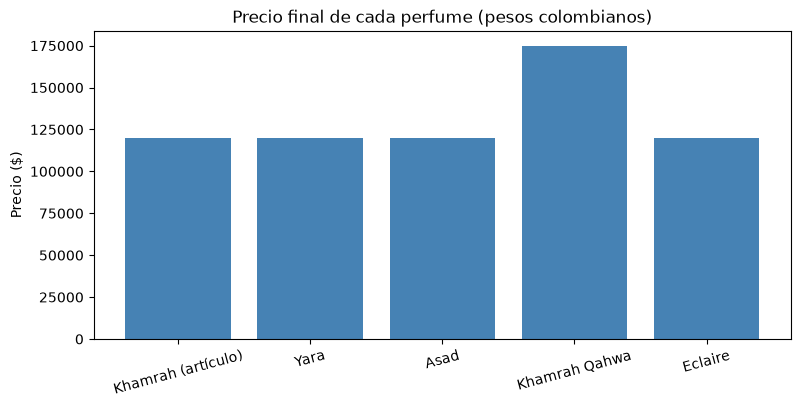

In [11]:
# Gráfica 1: precio final de cada perfume
plt.figure(figsize=(9, 4))
plt.bar(df["etiqueta"], df["precio"], color="steelblue")
plt.title("Precio final de cada perfume (pesos colombianos)")
plt.ylabel("Precio ($)")
plt.xticks(rotation=15)
plt.show()


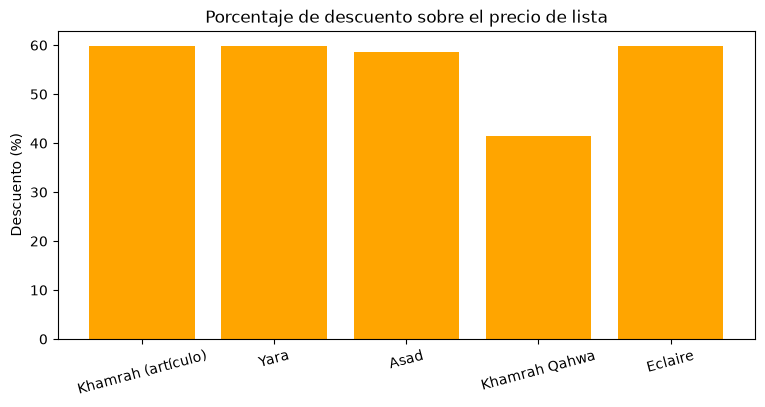

In [12]:
# Gráfica 2: porcentaje de descuento aplicado a cada perfume
plt.figure(figsize=(9, 4))
plt.bar(df["etiqueta"], df["descuento_%"], color="orange")
plt.title("Porcentaje de descuento sobre el precio de lista")
plt.ylabel("Descuento (%)")
plt.xticks(rotation=15)
plt.show()


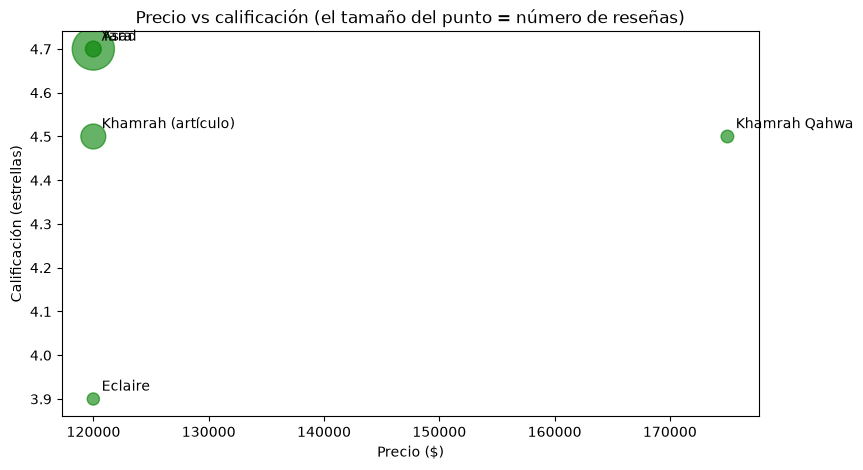

In [13]:
# Gráfica 3: precio vs calificación (el tamaño del punto indica número de reseñas)
plt.figure(figsize=(9, 5))
plt.scatter(df["precio"], df["calificacion"], s=df["resenas"], alpha=0.6, color="green")
for _, fila in df.iterrows():
    plt.annotate(fila["etiqueta"], (fila["precio"], fila["calificacion"]),
                 textcoords="offset points", xytext=(6, 6))
plt.xlabel("Precio ($)")
plt.ylabel("Calificación (estrellas)")
plt.title("Precio vs calificación (el tamaño del punto = número de reseñas)")
plt.show()


## Conclusiones

Todos los precios están en pesos colombianos.

- **Respuesta a la pregunta:** el Khamrah es una compra razonable (4.5 estrellas con
  322 reseñas por 119.990 pesos), pero no es la mejor opción de Lattafa en Falabella:
  por el mismo precio, **Yara** tiene mejor calificación (4.7) y casi el triple de
  reseñas (924).
- **El descuento no distingue al Khamrah:** Yara, Asad y Eclaire tienen el mismo
  precio final (119.990) y casi el mismo precio de lista (entre 290.000 y 299.000),
  con un descuento cercano al 60%. Lo aplica el vendedor (Amber Oud), no Falabella.
- **Khamrah Qahwa** cuesta 45.8% más que el Khamrah (174.990, descuento de solo
  41.5%) con la misma calificación (4.5) y menos reseñas: los datos no muestran nada
  que justifique ese precio.
- **Eclaire** cuesta lo mismo que el Khamrah y tiene la calificación más baja (3.9):
  el precio no siempre refleja la calidad percibida por los compradores.
- **Limitación:** son cinco productos y un solo día. Para saber si el precio de
  lista de 299.000 se cobra alguna vez (es decir, si el descuento es real) hay que
  repetir la extracción en el tiempo.

> **Si se vuelve a correr, los precios pueden ser otros.** Las salidas de arriba son
> de la ejecución del 26/10/2026 a las 10:14 a. m. En una segunda ejecución ese
> mismo día, a las 6:02 p. m., Khamrah, Yara, Asad y Eclaire ya costaban 149.900
> (descuento de 49.9%; Asad 48.3%) y el Khamrah Qahwa seguía en 174.990. El
> scraper funcionó igual: 5 de 5 productos y 5 de 5 precios iguales con
> BeautifulSoup. Lo que cambió fue la promoción.

## Control de versiones del proyecto

Este notebook hace parte del repositorio [analisis-datos-falabella](https://github.com/Sssir99/analisis-datos-falabella), que se trabajó con Git desde VS Code. En el repositorio quedan el notebook y el CSV que genera, así que cada cambio queda registrado y se puede volver a una versión anterior si algo se daña.

El flujo que se siguió fue: crear el repositorio en GitHub, conectar la carpeta del proyecto con `git remote add origin`, hacer un commit por cada cambio hecho y subirlo con `git push`. Los cambios nuevos se trabajaron en una rama aparte y se integraron a `main` con un Pull Request.

La celda de abajo muestra el repositorio al que está conectado el proyecto y los últimos commits que se subieron; solo lee, no modifica nada.

In [1]:
# Conexión con el repositorio y últimos commits (solo lectura)
!git remote -v
!git log --oneline -5

origin	https://github.com/Sssir99/analisis-datos-falabella.git (fetch)
origin	https://github.com/Sssir99/analisis-datos-falabella.git (push)


ef5c0b7 docs: seccion de control de versiones en el notebook
01001a9 Merge pull request #1 from Sssir99/docs/flujo-git
7634dd2 docs: seccion de control de versiones en el README
67e5fc8 docs: integrantes del equipo en el README
2931337 data: dataset de precios de perfumes extraido de Falabella
